```{contents}
:local:
:depth: 2
```

# 4.3 Hybrid Modeling

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 11, Lesson 1: *Hybrid Modeling Introduction*
- Module 11, Lesson 2: *Mechanism Correction*
- Module 11, Lesson 3: *Mechanism Identification*
- Module 11, Lesson 4: *Chemical Reactor Example*
- Module 11, Lesson 5: *HM Python Implementations*
- Module 12, Lesson 1: *Advanced Machine Learning in Python Part 1*
- Module 12, Lesson 2: *Advanced Machine Learning in Python Part 2*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Explain what a hybrid model is and why we would build one instead of a purely mechanistic or purely data-driven model.
- Distinguish parallel (mechanism correction) and serial (mechanism identification) hybrid structures.
- Train a black-box network, a discrepancy model and a network-inside-the-balances model in PyTorch, and compare them inside and outside the training region.
- Embed a trained network in a Pyomo model with OMLT and optimize through it, keeping the optimizer inside the training region.
:::

In Topics 3.1–3.6 we treated the process as a black box and replaced it with a surrogate fitted to samples. However, in chemical engineering it is rare to know nothing about the inside of the box. The conservation laws are almost always known, and the missing piece is usually one part of the model, such as a rate law, a transport coefficient or a property correlation. A **hybrid model** keeps the trusted parts of the model and uses data to learn only the unknown part. In this topic we will build the two main kinds of hybrid model, compare them on a reactor, and then put a trained network inside an optimization model.

## Mechanistic, data-driven and hybrid models

A **mechanistic model** (also called a first-principles or white-box model) is built from balances, kinetics, thermodynamics and transport laws. The parameters of a mechanistic model have physical meaning and relatively little data is needed to calibrate them, and the model generalizes well because a mass balance that holds at 340 K will also hold at 370 K. The main weakness is the cost of building the model, and there are also some phenomena (e.g. catalyst deactivation or fouling) that are hard to write down from first principles at all.

A **data-driven model** (or black-box model), such as a neural network or a Gaussian process, learns the input-output map from data. We can build one quickly even if we know very little about the physics, although it needs much more data and its parameters have no physical meaning. When we ask it to predict outside of the training data, it extrapolates according to its own functional form rather than according to the physics.

A **hybrid model** combines the two, and the lectures give three reasons why we would build one. The first is that the mechanistic model has every piece but still gives the wrong answer, because a parameter is inaccurate or because the plant does not obey an assumption that we made (such as first-order kinetics). The second is that the mechanistic model is missing a piece, such as a correlation that nobody has written down. The third is that we need to merge knowledge at several scales, for example if a molecular-simulation result is summarized by a surrogate inside a process model. Applications range from pH neutralization, methanol synthesis, polymerization, reactive distillation and crystallization to yeast and CHO-cell cultures and wastewater treatment (reviewed by von Stosch et al. 2014), and most of them use one of the two structures that are summarized in the table below.

| Structure | Also called | What the network learns | Where it sits |
|---|---|---|---|
| **Parallel** | mechanism correction, discrepancy modeling | the error of the mechanistic prediction | beside the mechanistic model; outputs are added or multiplied |
| **Serial** | mechanism identification, grey-box modeling | an unknown term, such as a rate | inside the balances; its output feeds the equations |

In the parallel structure the network is the last thing that the prediction passes through, while in the serial structure the last step is the balances. This ordering determines how each structure behaves when it is asked to extrapolate, and this is the main result of the topic.

The two structures can also be combined in a **serial-parallel** structure, where one network supplies an unknown term inside the balances and a second network corrects the output. In either structure the data-driven part can be any regression model, and studies cited in the lectures compared polynomials, neural and radial-basis-function networks, fuzzy networks, MARS splines, PLS and its nonlinear variants, and support vector machines. No model wins everywhere, and the choice of which inputs the data-driven part sees (input selection) often matters as much as the choice of model. We will use small neural networks throughout, since they are easy to train inside an ODE solver and easy to embed in Pyomo.

:::{exercise}
:label: ex-t43-structures

For a jacketed CSTR whose heat-transfer coefficient $U$ falls slowly as the wall fouls, sketch a parallel and a serial hybrid model. For each, state the network's inputs and outputs and which equations stay mechanistic. Which would you trust when the feed temperature is raised beyond the historical range, and why?
:::

## A reactor to model

We will use the same reactor in this topic and the next one. An isothermal plug-flow reactor (or a batch reactor, with residence time as batch time) carries out the series reaction $\mathrm{A} \rightarrow \mathrm{B} \rightarrow \mathrm{C}$, and we want to make as much of the intermediate B as possible. The mole balances in residence time $\tau$ are

$$
\frac{dC_A}{d\tau} = -r_1, \qquad \frac{dC_B}{d\tau} = r_1 - r_2, \qquad C_A(0) = 1\ \mathrm{mol/L}, \quad C_B(0) = 0.
$$

We will treat the balances as certain, and we will also treat the second step, $r_2 = k_2(T)\,C_B$, as certain, since we assume that it has been characterized in separate experiments. The uncertain part is the rate of the first step. The "plant", which we simulate to make data but pretend not to know, has an inhibited rate law,

$$
r_1 = \frac{k_1(T)\, C_A}{1 + K C_A}, \qquad K = 2\ \mathrm{L/mol},
$$

with Arrhenius constants $k_1 = 0.60\ \mathrm{min^{-1}}$ and $k_2 = 0.15\ \mathrm{min^{-1}}$ at 350 K and activation energies of 50 and 90 kJ/mol. The second step has the larger activation energy, so a hotter reactor makes B faster but also destroys it faster, which means that there is a best temperature for each residence time.

An engineer who did not know about the inhibition would write a first-order law, $r_1 = k_1(T) C_A$, which has a closed-form solution, and then fit $k_1$ to the data. This will be our **low-fidelity mechanistic model**. The data are concentration profiles at 330, 340, 350 and 360 K for residence times from 0.5 to 4 min, with a measurement noise of 0.01 mol/L. The helper `Reactor` in `_lib/part4b_tools.py` holds the plant and integrates it.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


32 measurements; fitted first-order k1(350 K) = 0.246 1/min
RMS misfit of the first-order model on its own training data: 0.0278 mol/L


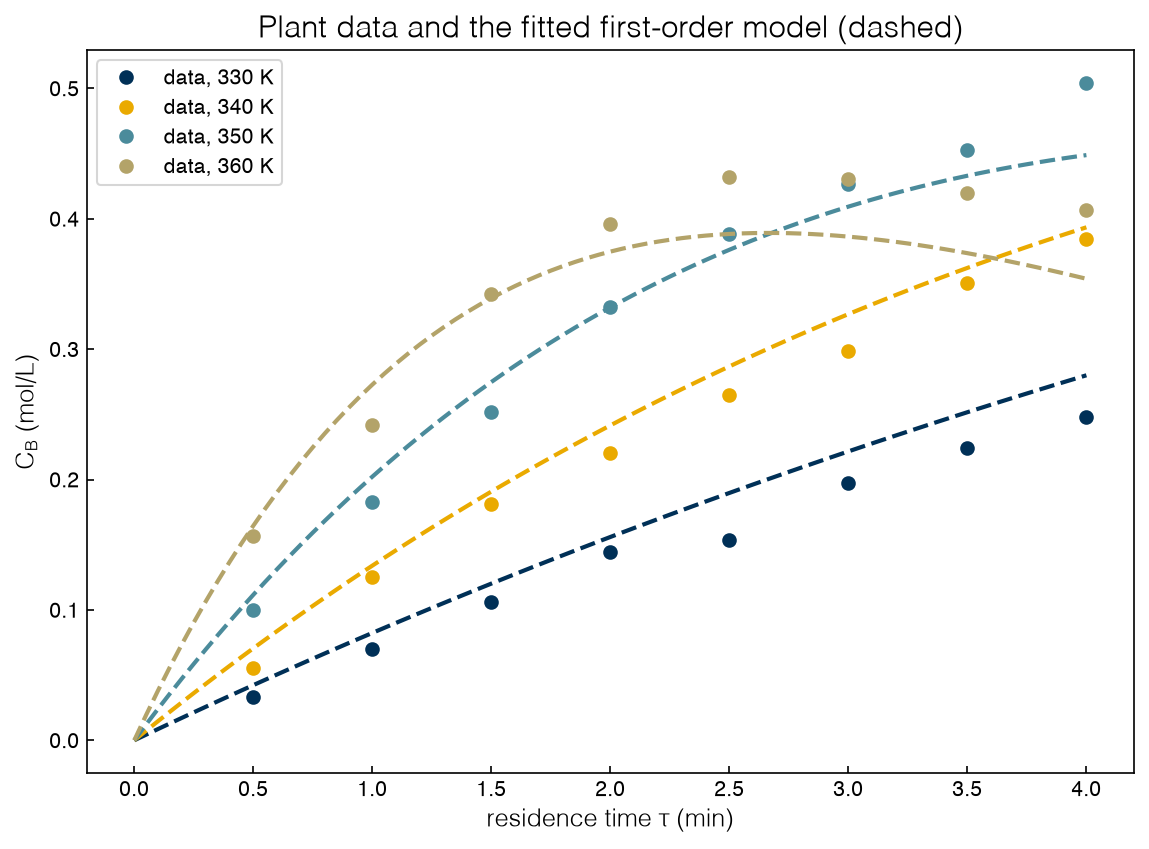

In [1]:
%matplotlib inline
import sys, time
sys.path.insert(0, '..')
import numpy as np
import torch
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import least_squares, minimize
from _lib.part4b_tools import Reactor as R, mlp, train, omlt_network, find_solver, rk4_reactor_pyomo

T_TRAIN = np.array([330., 340., 350., 360.])
TAU = np.arange(0.5, 4.01, 0.5)                                  # min
rng = np.random.default_rng(0)
data = R.measure(T_TRAIN, TAU, 0.01, rng)                        # rows: T, tau, C_A, C_B
val = R.measure([335., 345., 355.], TAU, 0.01, rng)              # held-out validation data

def first_order(T, tau, k1_ref):
    """Low-fidelity model: first-order A -> B plus the known B -> C step (closed form)."""
    k1 = k1_ref * np.exp(-R.E1 / R.R * (1 / T - 1 / R.T_REF))
    k2 = R.k2(T)
    return np.c_[np.exp(-k1 * tau), k1 / (k2 - k1) * (np.exp(-k1 * tau) - np.exp(-k2 * tau))]

k1_fit = least_squares(lambda p: (first_order(data[:, 0], data[:, 1], p[0]) - data[:, 2:]).ravel(), [0.3]).x[0]
rms_mech = np.sqrt(np.mean((first_order(data[:, 0], data[:, 1], k1_fit) - data[:, 2:]) ** 2))
print(f"{len(data)} measurements; fitted first-order k1(350 K) = {k1_fit:.3f} 1/min")
print(f"RMS misfit of the first-order model on its own training data: {rms_mech:.4f} mol/L")

tau_fine = np.linspace(0, 4, 81)
fig, ax = plt.subplots()
for T, col in zip(T_TRAIN, ['C0', 'C1', 'C2', 'C3']):
    rows = data[data[:, 0] == T]
    ax.plot(rows[:, 1], rows[:, 3], 'o', color=col, label=f'data, {T:.0f} K')
    ax.plot(tau_fine, first_order(T, tau_fine, k1_fit)[:, 1], '--', color=col)
ax.set_xlabel(r'residence time $\tau$ (min)')
ax.set_ylabel(r'$C_B$ (mol/L)')
ax.set_title('Plant data and the fitted first-order model (dashed)')
ax.legend(fontsize=10);

The fitted first-order constant of 0.246 min⁻¹ is well below the value of 0.60 in the plant. This happens because a single first-order constant has to average the inhibited rate over the whole range of $C_A$, and the misfit of about 0.028 mol/L is nearly three times the noise. The model does get the trends right, since B rises and then falls and it does so faster at higher temperature. However, the shapes are wrong, and there is no value of $k_1$ that will fix them. The lectures say that this situation (where we have the right trends but the wrong details) is the case for mechanism correction, and that a simplifying assumption can lead to the same situation. In the plug-flow reactor from the lectures, which is ethylbenzene dehydrogenation to styrene with side reactions to benzene and toluene, the low-fidelity model assumes that the reactor is isothermal. It misses the temperature profile, so it also misses the concentration profiles. In that case a discrepancy model on top of the isothermal model was accurate, because the isothermal model was already close and the data were not noisy.

:::{exercise}
:label: ex-t43-first-order

Refit the first-order model using only the 360 K profile, then only the 330 K profile. How different are the two fitted values of $k_1(350\ \mathrm{K})$? Explain the difference with the inhibition factor $1/(1 + K C_A)$ and the range of $C_A$ each profile covers.
:::

## Training networks in PyTorch

The Module 12 lectures build networks with TensorFlow and Keras, while this book uses PyTorch, but the ideas carry over one for one. Network basics (layers, activations, backpropagation, cross-entropy for classification) are covered in DA4CHE Topics 6.3 and 6.4 (https://www.medford.chbe.gatech.edu/DA4CHE/), so here we only give the map from one library to the other:

| Step | Keras (lectures) | PyTorch (this book) |
|---|---|---|
| define | `Sequential()` with `Dense` layers | `torch.nn.Sequential` with `Linear` layers and activations |
| loss and optimizer | `model.compile(loss='MSE', optimizer='Adam')` | a loss expression; `torch.optim.Adam(net.parameters())` |
| train | `model.fit(X, y, epochs, validation_data)` | a loop: zero gradients, loss, `backward()`, `step()` |
| monitor | the `history` from `fit` | record training and validation losses yourself |
| save | `model.save`, `load_model` | `torch.save(net.state_dict(), path)`, `net.load_state_dict(...)` |

The networks in scikit-learn are convenient, but they expose very little of the model. TensorFlow (developed by Google Brain) and PyTorch (developed by Meta's AI research lab) give full control of the architecture and the loss, and Keras is a higher-level interface to TensorFlow that sits between these and scikit-learn in terms of abstraction.

The same choices come up in each library. We need to choose the **layer type** (dense, or convolutional, pooling and recurrent layers for images and sequences, see DA4CHE Topic 6.4), the **width** and **depth**, the **loss** (mean squared error for regression, cross-entropy for classification), the **optimizer** (SGD, Adam, or L-BFGS for small full-batch problems) and its **learning rate**, the number of **epochs** (passes over the data), and the **batch size** (samples per gradient step, and our loops are full batch). The digits example in the lectures (8×8 images, 64 inputs) is first fitted as a regression on the value of the digit, and then reformulated as a 10-class classification with a cross-entropy loss, which is its natural form.

If we write the loop explicitly, it becomes clear that training is an optimization problem in the weights that is solved by a first-order method, which is what Topic 3.5 called optimization *for* training. Writing the loop ourselves also lets us put anything we like in the loss, including an ODE solver, which we will need for the serial hybrid.

Our **black-box** baseline is a network from $(T, \tau)$ to $(C_A, C_B)$ with two hidden layers of 16 tanh nodes. We scale the inputs to about $[-1, 1]$ to keep the tanh units in their useful range, and at every step we record the loss on held-out validation profiles at 335, 345 and 355 K.

black box: training MSE 5.09e-05, validation MSE 1.84e-04 (lowest 1.76e-04 at step 1277)


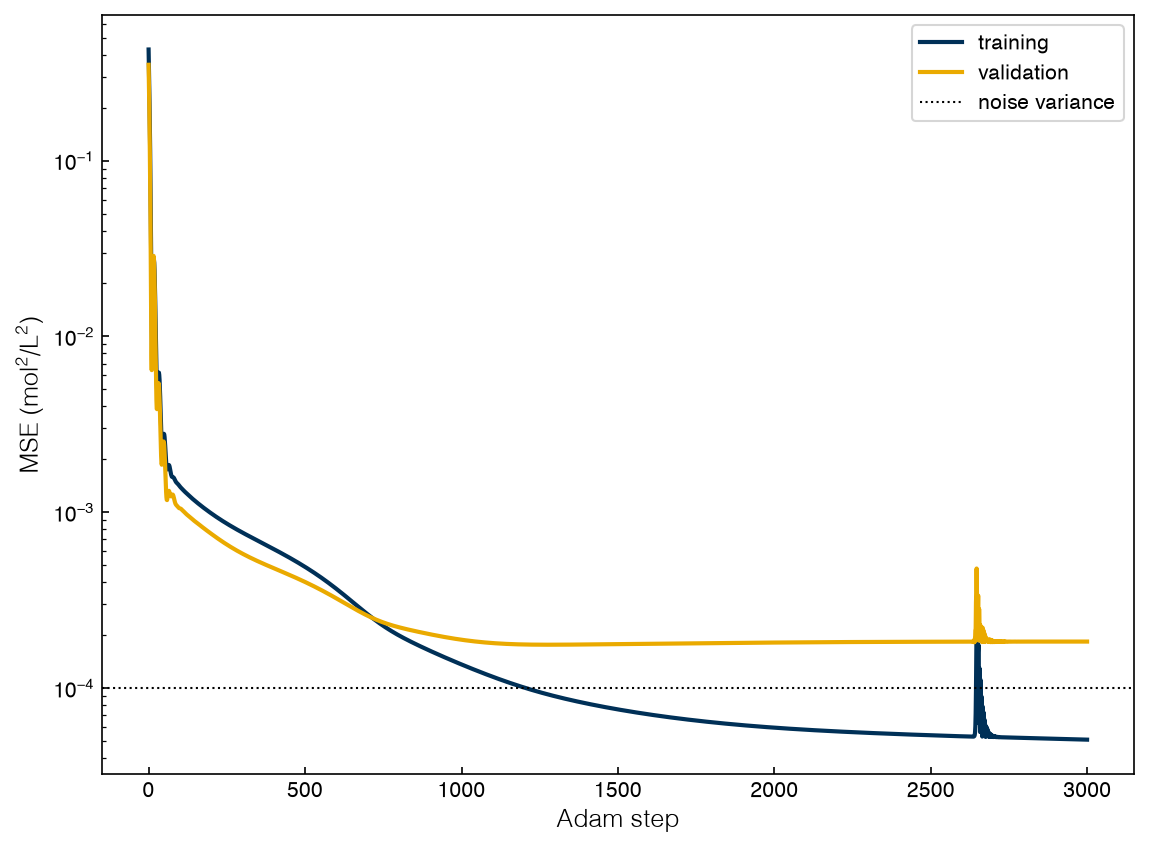

In [2]:
def scale(X):
    """(T, tau) -> roughly [-1, 1]."""
    return torch.tensor(np.c_[(X[:, 0] - 345) / 15, (X[:, 1] - 2.25) / 1.75])

X_tr, Y_tr = scale(data), torch.tensor(data[:, 2:])
X_va, Y_va = scale(val), torch.tensor(val[:, 2:])
bb = mlp(2, 2, width=16, depth=2, seed=0)
opt = torch.optim.Adam(bb.parameters(), lr=5e-3)
hist_tr, hist_va = [], []
for step in range(3000):
    opt.zero_grad()
    loss = ((bb(X_tr) - Y_tr) ** 2).mean()
    loss.backward()
    opt.step()
    with torch.no_grad():
        hist_tr.append(loss.item())
        hist_va.append(((bb(X_va) - Y_va) ** 2).mean().item())
print(f"black box: training MSE {hist_tr[-1]:.2e}, validation MSE {hist_va[-1]:.2e} "
      f"(lowest {min(hist_va):.2e} at step {int(np.argmin(hist_va))})")

fig, ax = plt.subplots()
ax.semilogy(hist_tr, label='training')
ax.semilogy(hist_va, label='validation')
ax.axhline(0.01 ** 2, color='k', ls=':', lw=1, label='noise variance')
ax.set_xlabel('Adam step')
ax.set_ylabel(r'MSE (mol$^2$/L$^2$)')
ax.legend();

The training loss falls below the noise variance (the floor below which a model is fitting noise), while the validation loss levels off near $1.8 \times 10^{-4}$. The validation data were held out of training, so the validation loss is the honest guide to how well the model predicts. The minimum of the validation loss is the natural place to stop training, although the lectures note that a clear minimum is rare, and usually the curve just flattens out like it does here. The width, depth, learning rate and number of steps are hyperparameters, and in the lectures these are tuned by grid search. DA4CHE covers cross-validated searches, and grid search over surrogate hyperparameters is covered in {doc}`../3-data_driven_optimization/Topic3.5-Surrogate_Models`. In this topic we keep the hyperparameters fixed so that the comparisons below are fair.

:::{exercise}
:label: ex-t43-width

Retrain the black box with 4, 16 and 64 nodes per hidden layer (same seed) and plot the validation curves together. Which width overfits, and how can you tell? Save the best network with `torch.save(bb.state_dict(), 'bb.pt')` and reload it into a fresh `mlp`.
:::

## Mechanism correction: the parallel structure

In mechanism correction the first-order model runs unchanged, and a second network learns its error, i.e. the **discrepancy** between the data and the model: $\hat{C}(T, \tau) = C^{\text{mech}}(T, \tau) + \mathrm{NN}(T, \tau)$. This works when the error is systematic, meaning that it is a smooth function of the inputs. A map of the error is also useful in its own right, since it shows where the model over- or under-predicts and where new experiments would reduce the error the most, and it can be carried into an optimization as a correction to the mechanistic prediction.

The lectures make a second point with a fed-batch penicillin case study, which is that the mechanistic model acts as a **noise filter**. It turns noisy measurements into a smooth trend, so the network only has to learn a small, smooth residual, and the benefit over a black box grows as the data get noisier or sparser.

In [3]:
resid = torch.tensor(data[:, 2:] - first_order(data[:, 0], data[:, 1], k1_fit))
par = mlp(2, 2, width=16, depth=2, seed=0)
train(par.parameters(), lambda: ((par(X_tr) - resid) ** 2).mean(), steps=3000, lr=5e-3)

def predict_parallel(X):
    with torch.no_grad():
        return first_order(X[:, 0], X[:, 1], k1_fit) + par(scale(X)).numpy()

rms_par = np.sqrt(np.mean((predict_parallel(data) - data[:, 2:]) ** 2))
print(f"parallel hybrid: training RMS misfit {rms_par:.4f} mol/L (first-order alone: {rms_mech:.4f})")

parallel hybrid: training RMS misfit 0.0056 mol/L (first-order alone: 0.0278)


The correction brings the training misfit below the noise level, just like the black box does, so the two models look the same on the training data. The difference will show up when we leave the training region, or when the data are noisier.

In the penicillin study from the lectures the black box and the hybrid had similar errors when the data were clean, and the advantage of the hybrid only appeared with noisy data and missing values. We can test the noise-filter argument directly by making the noise five times larger (0.05 mol/L). A 16-node network will fit this noise, so for both models we use a deliberately small network with one hidden layer of 4 nodes, and we compare them over three noise seeds at the interpolation temperatures and at residence times from 4.5 to 6 min.

In [4]:
quiet = np.random.default_rng(1)
X_int = R.measure([335., 345., 355.], TAU, 0.0, quiet)
X_ext = R.measure(T_TRAIN, np.arange(4.5, 6.01, 0.5), 0.0, quiet)
rms = lambda pred, Z: np.sqrt(np.mean((pred(Z)[:, 1] - Z[:, 3]) ** 2))
results = {'black box': [], 'parallel': []}
for seed in range(3):
    noisy = R.measure(T_TRAIN, TAU, 0.05, np.random.default_rng(seed))
    k = least_squares(lambda p: (first_order(noisy[:, 0], noisy[:, 1], p[0]) - noisy[:, 2:]).ravel(), [0.3]).x[0]
    Xn, Yn = scale(noisy), torch.tensor(noisy[:, 2:])
    small_bb, small_par = mlp(2, 2, width=4, depth=1, seed=0), mlp(2, 2, width=4, depth=1, seed=0)
    res_n = Yn - torch.tensor(first_order(noisy[:, 0], noisy[:, 1], k))
    train(small_bb.parameters(), lambda: ((small_bb(Xn) - Yn) ** 2).mean(), steps=1500, lr=5e-3)
    train(small_par.parameters(), lambda: ((small_par(Xn) - res_n) ** 2).mean(), steps=1500, lr=5e-3)
    f_bb = lambda Z: small_bb(scale(Z)).detach().numpy()
    f_par = lambda Z, k=k: first_order(Z[:, 0], Z[:, 1], k) + small_par(scale(Z)).detach().numpy()
    results['black box'].append((rms(f_bb, X_int), rms(f_bb, X_ext)))
    results['parallel'].append((rms(f_par, X_int), rms(f_par, X_ext)))
for name, r in results.items():
    r = np.array(r)
    print(f"noise 0.05 mol/L, 4-node network, {name:9s}: RMS error in C_B, interpolation "
          f"{r[:, 0].mean():.4f}, tau 4.5-6 min {r[:, 1].mean():.4f} (mean of 3 seeds)")

noise 0.05 mol/L, 4-node network, black box: RMS error in C_B, interpolation 0.0297, tau 4.5-6 min 0.1105 (mean of 3 seeds)
noise 0.05 mol/L, 4-node network, parallel : RMS error in C_B, interpolation 0.0169, tau 4.5-6 min 0.0637 (mean of 3 seeds)


With the small network, the errors of the parallel hybrid are about half of the black-box errors, both between the training temperatures (0.017 against 0.030 mol/L) and at longer residence times (0.064 against 0.111 mol/L). The small black box cannot represent the curved profiles on its own, but the small correction network only has to represent a residual, since the first-order model already supplies the shape. This is how the mechanistic part acts as a noise filter: noisy data force us to keep the network simple, and a simple network is only enough when the mechanistic model carries the trend.

The lectures also point out the limits of correction. One open question is how wrong the mechanistic model can be before its trends start to mislead the network. Since the prediction still ends in a network, the hybrid cannot claim to extrapolate any better than its network does, and a network that is too flexible will fit the noise rather than the error (which is why we shrank it above).

:::{exercise}
:label: ex-t43-multiplicative

Build a multiplicative correction, $\hat{C}_B = C_B^{\text{mech}} (1 + \mathrm{NN}(T, \tau))$, train it on the same data, and compare its training misfit with the additive one. Which structure guarantees $\hat{C}_B = 0$ at $\tau = 0$?
:::

## Mechanism identification: the serial structure

In mechanism identification the network goes inside the balances and replaces the unknown term, which in this case is the rate of the first step:

$$
\frac{dC_A}{d\tau} = -\hat r_1(C_A, T), \qquad \frac{dC_B}{d\tau} = \hat r_1(C_A, T) - k_2(T)\, C_B.
$$

No matter what rate the network predicts, the concentrations are computed from the mole balances, so species are conserved, the known second step is applied exactly, and every profile starts from the feed.

There are two choices left. The first is how much physics to build into $\hat r_1$ itself. A plain network can predict a nonzero rate when there is no A left, which is physically impossible, so instead we write $\hat r_1 = C_A \cdot s(\mathrm{NN}(C_A, T))$ with $s(z) = 0.3 \ln(1 + e^{z})$. The softplus function $s$ keeps the apparent rate constant positive, and the factor of 0.3 min⁻¹ only sets its scale. In effect, this is a first-order rate law where the rate constant is learned as a function of concentration and temperature.

How should we train the network? The lectures describe two approaches. **Sequential training** first estimates rates from the data (by differentiating smoothed profiles), then fits the network to those rates, and then solves the ODEs. Each step is easy, but differentiating noisy data amplifies the noise. **Integrated training** fits the weights so that the *solution of the ODEs* matches the measured concentrations. In the lectures this is set up as one large, nonconvex Pyomo parameter-estimation problem, which is best initialized from black-box weights. Automatic differentiation makes integrated training routine, since we can write a fixed-step fourth-order Runge–Kutta (RK4) integrator in PyTorch, and then the gradient of the loss with respect to the weights flows back through every step of the integrator. This is a small example of what is often called a neural ODE.

It is useful to write the two approaches as optimization problems, since then it is clear that they differ in where the ODEs sit. With weights $w$, states $X$ (concentrations), the balances $h(X, r) = 0$ and the rate network $r(X, w)$, integrated training is

$$
\min_{w}\; \sum_{\text{data}} \big(X - X^{\text{meas}}\big)^2 \quad \text{s.t.} \quad h\big(X, r(X, w)\big) = 0,
$$

while sequential training first solves $\min_w \sum (r(X^{\text{meas}}, w) - R^{\text{est}})^2$ against the rate estimates $R^{\text{est}}$, and only then integrates $h = 0$ with the trained network. In the fermentation example from the lectures there are biomass, substrate, product and dissolved-oxygen balances with rates that are predicted by networks, and the integrated problem is written directly in Pyomo with the balances and the network together and the weights as variables. The lectures also list why this is difficult. There are many parameters, and since the objective weights several measured states, those weights become hyperparameters. The problem is also nonconvex, so global solvers are impractical and local solvers will often stop at infeasible points. This is why the lectures suggest that we initialize from black-box weights, i.e. from a black-box network that was trained separately.

In [5]:
H = 0.25                                   # RK4 step, min
idx = np.round(TAU / H).astype(int)        # steps at which data are measured
rnet = mlp(2, 1, width=16, depth=2, seed=0)

def rate_nn(ca, Ts):
    """Learned first-step rate, mol/(L min): C_A times a positive apparent rate constant."""
    return ca * 0.3 * torch.nn.functional.softplus(rnet(torch.stack([ca, Ts], 1))[:, 0])

def simulate_serial(temps, tau_max):
    """Integrate the balances with the learned r1 by RK4. Returns an array (steps+1, n_T, 2)."""
    temps = np.atleast_1d(np.asarray(temps, float))
    Ts, k2 = torch.tensor((temps - 345) / 15), torch.tensor(R.k2(temps))
    def f(c):
        r1 = rate_nn(c[:, 0], Ts)
        return torch.stack([-r1, r1 - k2 * c[:, 1]], 1)
    c = torch.zeros(len(temps), 2, dtype=torch.double); c[:, 0] = R.CA0
    traj = [c]
    for _ in range(int(round(tau_max / H))):
        a = f(c); b = f(c + H / 2 * a); d = f(c + H / 2 * b); e = f(c + H * d)
        c = c + H / 6 * (a + 2 * b + 2 * d + e)
        traj.append(c)
    return torch.stack(traj)

Y_prof = torch.tensor(data[:, 2:].reshape(len(T_TRAIN), len(TAU), 2).transpose(1, 0, 2))
t0 = time.time()
hist = train(rnet.parameters(), lambda: ((simulate_serial(T_TRAIN, 4.0)[idx] - Y_prof) ** 2).mean(),
             steps=1500, lr=5e-3)
print(f"serial hybrid: training MSE {hist[-1]:.2e} ({time.time() - t0:.1f} s of integrated training)")
ca_grid = np.array([0.2, 0.5, 0.8])
for T in (330., 360.):
    with torch.no_grad():
        learned = rate_nn(torch.tensor(ca_grid), torch.full((3,), (T - 345) / 15, dtype=torch.double))
    print(f"T = {T:.0f} K, C_A = {ca_grid}: true r1 = {np.round(R.r1_true(ca_grid, T), 3)}, "
          f"learned r1 = {np.round(learned.numpy(), 3)}")

serial hybrid: training MSE 7.30e-05 (6.3 s of integrated training)
T = 330 K, C_A = [0.2 0.5 0.8]: true r1 = [0.03  0.053 0.065], learned r1 = [0.024 0.05  0.066]
T = 360 K, C_A = [0.2 0.5 0.8]: true r1 = [0.138 0.242 0.298], learned r1 = [0.126 0.249 0.299]


The network was never shown a rate, only concentrations, but the rates that it learned match the inhibited rate law of the plant within about 5% wherever the data are informative. The one larger miss is at 330 K and $C_A = 0.2$, which is a state that the data never visit, since at 330 K so little A reacts that $C_A$ stays above about 0.7 mol/L. Because the learned rate can be plotted, inspected and compared with candidate rate laws, we say that the serial structure *identifies* the mechanism.

The serial structure also has some costs. The mechanistic model must be open to modification, which is often not the case for legacy simulation code, every evaluation of the loss requires integrating the model, and identification gets harder when several terms are unknown at the same time. In the plug-flow reactor from the lectures all three rates were unknown and learned, and the identified model captured the trends but kept a visible error. This error reflects the fact that missing every rate term is a harder problem, and it does not mean that identification is a worse approach. Mechanistic knowledge can also be vast (e.g. a cell-signaling pathway has hundreds of reactions), and in these cases a hybrid model may be the only practical way to fill in the gaps.

The benefit that we get in exchange is the ability to extrapolate through the white-box part of the model. Te Braake, van Can and Verbruggen (1998) showed that this works for process scale-up, since the kinetics that the network learns do not depend on scale and the balances that do depend on scale carry the model to the larger unit. A black box that is trained at the small scale fails.

:::{exercise}
:label: ex-t43-plain-rate

Replace `rate_nn` with a plain network, `0.3 * rnet(...)[:, 0]`, with no factor $C_A$ and no softplus. Retrain it, print the learned rate at $C_A = 0$ for 330 and 360 K, and repeat the extrapolation comparison of the next section. What does the missing structure cost?
:::

## Interpolation versus extrapolation

We test the four models on noise-free plant predictions in three regions, which are **interpolation** (335, 345 and 355 K, at the training residence times), **longer residence times** (the training temperatures, with $\tau$ from 4.5 to 8 min), and a **hotter reactor** (370 K, which is 10 K above the data).

RMS error in C_B (mol/L)    first-order    black box     parallel       serial
interpolation                    0.0234       0.0070       0.0073       0.0023
tau 4.5-8 min                    0.0371       0.0826       0.0689       0.0076
T = 370 K                        0.0312       0.0473       0.0123       0.0132


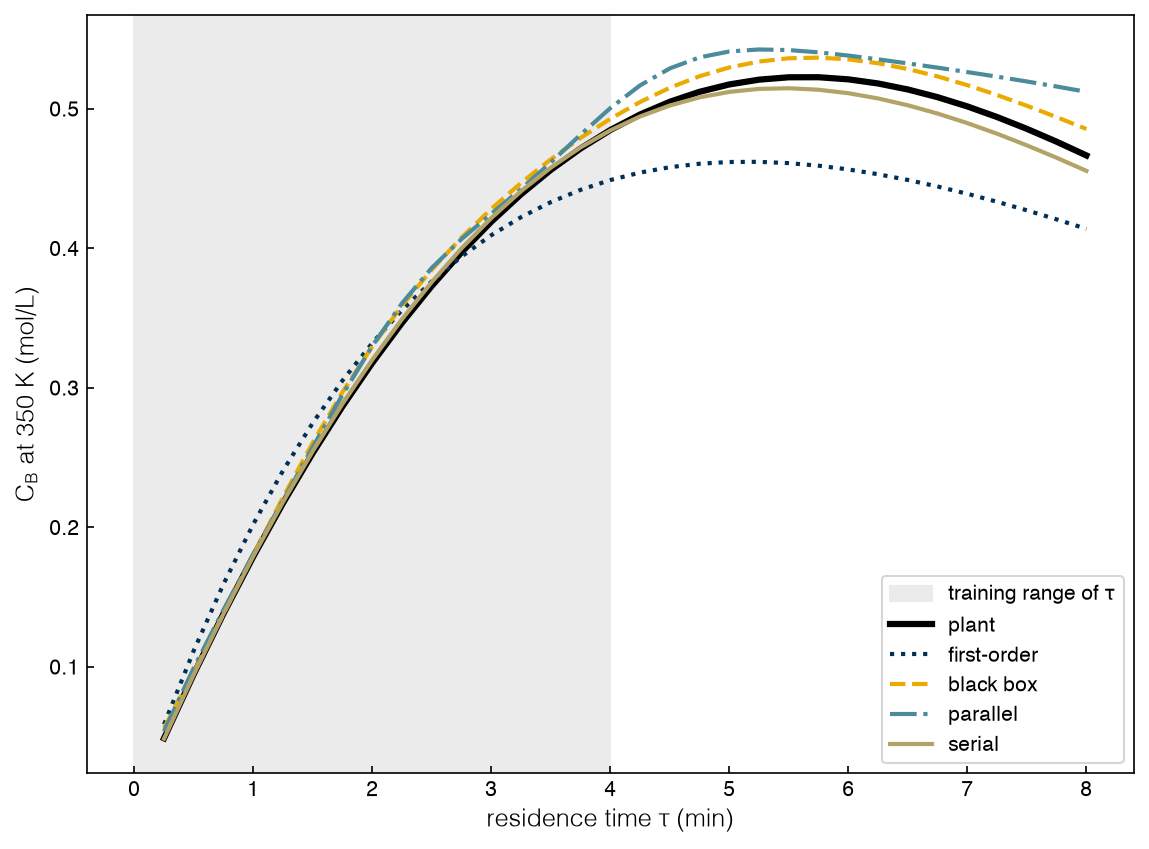

In [6]:
def predict_serial(X):
    out = np.zeros((len(X), 2))
    for T in np.unique(X[:, 0]):
        rows = X[:, 0] == T
        with torch.no_grad():
            traj = simulate_serial([T], X[rows, 1].max()).numpy()[:, 0, :]
        out[rows] = traj[np.round(X[rows, 1] / H).astype(int)]
    return out

models = {'first-order': lambda X: first_order(X[:, 0], X[:, 1], k1_fit),
          'black box': lambda X: bb(scale(X)).detach().numpy(),
          'parallel': predict_parallel, 'serial': predict_serial}
quiet = np.random.default_rng(1)
tests = {'interpolation': R.measure([335., 345., 355.], TAU, 0.0, quiet),
         'tau 4.5-8 min': R.measure(T_TRAIN, np.arange(4.5, 8.01, 0.5), 0.0, quiet),
         'T = 370 K': R.measure([370.], TAU, 0.0, quiet)}
print(f"{'RMS error in C_B (mol/L)':26s}" + ''.join(f"{n:>13s}" for n in models))
for name, X in tests.items():
    errs = [np.sqrt(np.mean((f(X)[:, 1] - X[:, 3]) ** 2)) for f in models.values()]
    print(f"{name:26s}" + ''.join(f"{e:13.4f}" for e in errs))

tau_long = np.arange(0.25, 8.01, 0.25)
X = np.c_[np.full_like(tau_long, 350.), tau_long]
fig, ax = plt.subplots()
ax.axvspan(0, 4, color='0.92', label=r'training range of $\tau$')
ax.plot(tau_long, R.simulate(350., tau_long, n=100)[1], 'k-', lw=3, label='plant')
for name, ls in zip(models, [':', '--', '-.', '-']):
    ax.plot(tau_long, models[name](X)[:, 1], ls, label=name)
ax.set_xlabel(r'residence time $\tau$ (min)')
ax.set_ylabel(r'$C_B$ at 350 K (mol/L)')
ax.legend(fontsize=10);

Inside the training region all three data-driven models beat the first-order model and predict below the 0.01 mol/L noise level, and the serial hybrid is the most accurate (0.002 mol/L). Outside of the training region the models start to separate.

- At **longer residence times** the black box and the parallel hybrid miss by 0.08 and 0.07 mol/L, worse than the uncorrected first-order model, because both end in a network whose input $\tau$ is now out of range. The serial hybrid stays below 0.01 mol/L. Its network never sees $\tau$ as an input; it sees $C_A$ and $T$, and at long residence times $C_A$ is still within the range that the hotter training profiles covered, so the balances carry the prediction forward.
- At **370 K** every network's input $T$ is out of range. The parallel and serial hybrids are similar (0.012 and 0.013 mol/L) and much better than the black box. The serial model has no structural advantage here, because its rate network is itself extrapolating in temperature.

In general, a model that ends in a network is only as good as the extrapolation of the network, while a model that ends in the balances inherits the generality of the balances, as long as the inputs to the network itself stay within the range of the data.

:::{exercise}
:label: ex-t43-arrhenius

Give the serial model the Arrhenius form, $\hat r_1 = k_1^{\text{fit}}(T)\, C_A\, s(\mathrm{NN}(C_A))$, so that the known activation energy carries the temperature dependence and the network sees only $C_A$. Retrain it and recompute the 370 K row. Why does this version extrapolate in temperature when the two-input version does not?
:::

## Optimization with an embedded network

In Topic 3.5 we separated optimization *for* training a model from optimization *with* a trained model that is embedded in a larger problem. So far we have done the first one, and now we will do the second, by writing the trained network as algebraic constraints in Pyomo and optimizing the process through it.

In the lectures, each tanh node of a Keras network is written by hand as a Pyomo expression. The Optimization and Machine Learning Toolkit (**OMLT**) automates this by building a Pyomo block with a variable for each node, and it exposes the `inputs` and `outputs` of the network. For tanh it writes a smooth NLP (`FullSpaceSmoothNNFormulation`) for Ipopt, and for ReLU it can write an exact big-M MILP (Topic 2.4) that a MILP solver will solve globally. OMLT reads ONNX files, which is the usual route from PyTorch, but our helper `omlt_network` just copies the weights directly.

### Warm-up: a network as a constraint

:::{admonition} Adapted from the course notebook
:class: note
Adapted from `NeuralNets-HybridModels-PINNs.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), section "Hybrid Modeling: Incorporating ML Models into Pyomo". Modernized: PyTorch replaces Keras, Latin hypercube sampling replaces uniform random sampling, and OMLT replaces the hand-written network constraint.
:::

As a test problem, we will minimize the Rosenbrock function $(1-x)^2 + 100(y - x^2)^2$ over $x, y \in [-2, 2]$ subject to $\sin x \sin y \le 0.6$. We will pretend that the constraint function is expensive to evaluate, so that we have to sample it, fit a network, and then use the network in place of the constraint. The version in the lectures draws 3,000 random samples, which assumes that sampling is cheap, but here we find that 400 Latin-hypercube samples are enough.

In [7]:
import pyomo.environ as pyo
from scipy.stats import qmc
from omlt import OmltBlock
from omlt.neuralnet import FullSpaceSmoothNNFormulation

ipopt = find_solver('ipopt')
print('Ipopt found' if ipopt else 'Ipopt not found: optimization cells fall back to scipy')

XY = qmc.scale(qmc.LatinHypercube(d=2, seed=0).random(400), [-2, -2], [2, 2])
g = torch.tensor((np.sin(XY[:, 0]) * np.sin(XY[:, 1]))[:, None])
gnet = mlp(2, 1, width=10, depth=2, seed=0)
h = train(gnet.parameters(), lambda: ((gnet(torch.tensor(XY / 2)) - g) ** 2).mean(), steps=2000, lr=1e-2)
print(f"constraint network: training RMS error {np.sqrt(h[-1]):.4f} on 400 samples")

def rosenbrock(use_network):
    m = pyo.ConcreteModel()
    m.x = pyo.Var(bounds=(-2, 2), initialize=-1.2)
    m.y = pyo.Var(bounds=(-2, 2), initialize=1.0)
    m.obj = pyo.Objective(expr=(1 - m.x) ** 2 + 100 * (m.y - m.x ** 2) ** 2)
    if use_network:
        m.nn = OmltBlock()
        m.nn.build_formulation(FullSpaceSmoothNNFormulation(
            omlt_network(gnet, [0, 0], [2, 2], [0], [1], input_bounds=[(-2, 2), (-2, 2)])))
        m.link = pyo.Constraint([0, 1], rule=lambda m, i: m.nn.inputs[i] == (m.x, m.y)[i])
        m.con = pyo.Constraint(expr=m.nn.outputs[0] <= 0.6)
    else:
        m.con = pyo.Constraint(expr=pyo.sin(m.x) * pyo.sin(m.y) <= 0.6)
    return m

for use_network in (False, True):
    if ipopt:
        m = rosenbrock(use_network); ipopt.solve(m); x, y = pyo.value(m.x), pyo.value(m.y)
    else:
        gfun = (lambda z: gnet(torch.tensor(np.array([z]) / 2)).item()) if use_network else \
               (lambda z: np.sin(z[0]) * np.sin(z[1]))
        x, y = minimize(lambda z: (1 - z[0]) ** 2 + 100 * (z[1] - z[0] ** 2) ** 2, [-1.2, 1],
                        bounds=[(-2, 2)] * 2, constraints={'type': 'ineq', 'fun': lambda z: 0.6 - gfun(z)}).x
    print(f"{'network' if use_network else 'exact  '} constraint: x = {x:.4f}, y = {y:.4f}, "
          f"true sin(x)sin(y) = {np.sin(x) * np.sin(y):.4f}")

Ipopt found


constraint network: training RMS error 0.0128 on 400 samples


exact   constraint: x = 0.9230, y = 0.8517, true sin(x)sin(y) = 0.6000


network constraint: x = 0.9205, y = 0.8471, true sin(x)sin(y) = 0.5964


Without the constraint the minimum is at $(1, 1)$, where $\sin 1 \sin 1 = 0.708$, so we know that the constraint is active. When the network is used in place of the constraint, the solver lands within 0.005 of the exact solution $(0.923, 0.852)$, at a point where the true constraint is 0.596 rather than 0.6. This shows that the small fitting error of the network has turned into a small error in where the constraint binds, and in general an embedded model is only as accurate as its fit near the optimum. The notebook also compares one- and two-hidden-layer networks as the constraint, along with the solve times of the network and exact formulations. Each node in the network adds a variable and a constraint, so deeper and wider networks cost more per solve, although at this size both of the solves take a fraction of a second.

### Optimizing the reactor through the serial hybrid

Now we can choose $T \in [330, 360]$ K and $\tau \in [0.5, 4]$ min to maximize the outlet $C_B$ with the serial hybrid. The helper `rk4_reactor_pyomo` writes the RK4 integrator as algebraic constraints with 16 steps of length $\tau/16$, and at each of the four stages of each step an OMLT block evaluates the learned rate from the $C_A$ and $T$ of that stage, which gives 64 copies of the network in all. This is the same integrator as the PyTorch version above, just written in Pyomo.

The bounds match the training region on purpose, and OMLT also bounds the inputs of the network to $C_A \in [0, 1]$, $T \in [330, 360]$ K. An optimizer will find any place where a data-driven model is wrong in its favor, and these places are almost always outside of the data, so bounding the inputs to the training region is the simplest way to guard against them.

In [8]:
rate_def = omlt_network(rnet, x_offset=[0, 345], x_factor=[1, 15], y_offset=[0], y_factor=[1],
                        input_bounds=[(0, 1), (330, 360)])
m = rk4_reactor_pyomo(rate_def, n_steps=16, T_bounds=(330, 360), tau_bounds=(0.5, 4))
if ipopt:
    res = ipopt.solve(m)
    T_hyb, tau_hyb, cb_hyb = pyo.value(m.T), pyo.value(m.tau), pyo.value(m.cb[16])
    print(f"Ipopt: {res.solver.termination_condition}")
else:   # fallback: optimize T with scipy at the 4 min bound
    with torch.no_grad():
        best = minimize(lambda z: -float(simulate_serial([z[0]], 4.0)[-1, 0, 1]), [345.],
                        bounds=[(330, 360)], method='Nelder-Mead')
    T_hyb, tau_hyb, cb_hyb = best.x[0], 4.0, -best.fun

plant_cb = lambda z: R.simulate(z[0], [z[1]], n=200)[1][0]
box, starts = [(330, 360), (0.5, 4)], [(335, 2), (355, 3)]
true = min((minimize(lambda z: -plant_cb(z), s, bounds=box) for s in starts), key=lambda r: r.fun)
mech = min((minimize(lambda z: -first_order(*z, k1_fit)[0, 1], s, bounds=box) for s in starts), key=lambda r: r.fun)
print(f"{'':22s}{'T (K)':>8s}{'tau (min)':>11s}{'predicted C_B':>15s}{'plant C_B':>11s}")
print(f"{'serial hybrid (OMLT)':22s}{T_hyb:8.1f}{tau_hyb:11.2f}{cb_hyb:15.4f}{plant_cb((T_hyb, tau_hyb)):11.4f}")
print(f"{'first-order model':22s}{mech.x[0]:8.1f}{mech.x[1]:11.2f}{-mech.fun:15.4f}{plant_cb(mech.x):11.4f}")
print(f"{'true optimum':22s}{true.x[0]:8.1f}{true.x[1]:11.2f}{'':15s}{-true.fun:11.4f}")

Ipopt: optimal
                         T (K)  tau (min)  predicted C_B  plant C_B
serial hybrid (OMLT)     352.0       4.00         0.4883     0.4888
first-order model        349.5       4.00         0.4490     0.4825
true optimum             352.0       4.00                    0.4888


| | $T$ (K) | $\tau$ (min) | predicted $C_B$ (mol/L) | plant $C_B$ (mol/L) |
|---|---|---|---|---|
| serial hybrid (OMLT) | 352.0 | 4.00 | 0.4883 | 0.4888 |
| first-order model | 349.5 | 4.00 | 0.4490 | 0.4825 |
| true optimum | 352.0 | 4.00 | | 0.4888 |

The table shows that the optimizer has found the true optimum of the plant by going to the 4 min bound and an interior temperature. At this point the plant would give the true maximum of B to four decimals, which is very close to the prediction of the hybrid. With the first-order model the optimizer also goes to the bound on $\tau$, but picks a cooler reactor because the dependence of the rate on $C_A$ is wrong in that model. The first-order prediction for the amount of B is also too low. Since the optimum is flat in $T$, the decision of the first-order model only costs about 1% of the achievable B, but the predicted value is off by about 7%.

The optimum sits on the $\tau$ bound, which is also the edge of the training data. If we lift that bound the optimizer will have to extrapolate, and the previous section showed that this is relatively safe for the serial hybrid and unsafe for the black box.

:::{exercise}
:label: ex-t43-omlt

Embed the black box `bb` with OMLT (one block with inputs $T$ and $\tau$, scaled as in `scale`) and maximize its predicted $C_B$ over the same box. Compare its optimum, and the plant's $C_B$ there, with the serial hybrid's. Then widen the $\tau$ bound to 8 min for both. Which optimum moves to a point where the plant disagrees with the model, and by how much?
:::

## Summary

- **Parallel** hybrids (mechanism correction) add a learned discrepancy to an unchanged mechanistic model. The mechanistic model acts as a noise filter, but the prediction ends in a network and extrapolates like one.
- **Serial** hybrids (mechanism identification) put the network inside the balances. Trained through an ODE solver, ours learned the never-measured rate of A → B within about 5% where the data are informative.
- At residence times twice those in the data, the black box and the parallel hybrid missed by 0.07 to 0.08 mol/L; the serial hybrid stayed below 0.01 mol/L.
- OMLT writes a trained network as Pyomo constraints. Optimizing through 64 copies of the learned rate recovered the plant's optimum, 352 K at the 4 min bound. Keep embedded networks inside their training region.
- {doc}`Topic4.4-Physics-Informed_Machine_Learning` puts the physics into the training loss instead of around the network.

## Additional Reading

- D. C. Psichogios and L. H. Ungar, "A hybrid neural network-first principles approach to process modeling," *AIChE Journal* 38 (1992) 1499–1511. The original serial structure.
- M. L. Thompson and M. A. Kramer, "Modeling chemical processes using prior knowledge and neural networks," *AIChE Journal* 40 (1994) 1328–1340. The parallel structure and the fed-batch penicillin example.
- H. A. B. te Braake, H. J. L. van Can and H. B. Verbruggen, "Semi-mechanistic modeling of chemical processes with neural networks," *Engineering Applications of Artificial Intelligence* 11 (1998) 507–515.
- M. von Stosch, R. Oliveira, J. Peres and S. Feyo de Azevedo, "Hybrid semi-parametric modeling in process systems engineering: Past, present and future," *Computers & Chemical Engineering* 60 (2014) 86–101.
- F. Ceccon, J. Jalving, J. Haddad, A. Thebelt, C. Tsay, C. D. Laird and R. Misener, "OMLT: Optimization & Machine Learning Toolkit," *Journal of Machine Learning Research* 23 (2022) 1–8.
- L. T. Biegler, *Nonlinear Programming: Concepts, Algorithms, and Applications to Chemical Processes*, SIAM (2010). The simultaneous (discretize-then-optimize) approach used in the last example.